In [ ]:
from google.colab import drive

# Try force remount to refresh any previous session conflicts
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report
import numpy as np
import os
import matplotlib.pyplot as plt
from tensorflow.keras.optimizers import Adam

In [ ]:
# Define dataset path
dataset_path = "/content/drive/MyDrive/soybean"  # Change this to your dataset directory

In [ ]:
# Check if dataset path exists
if not os.path.exists(dataset_path):
    raise ValueError(f"Dataset path '{dataset_path}' does not exist. Please check the path.")

In [ ]:
# Load dataset using ImageDataGenerator with data augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,  # 80% training, 20% validation
    rotation_range=30,
    width_shift_range=0.3,
    height_shift_range=0.3,
    shear_range=0.3,
    zoom_range=0.3,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],  # Adding brightness range augmentation
    channel_shift_range=50.0  # Adding color channel shift for better generalization
)

# Train generator
train_generator = train_datagen.flow_from_directory(
    dataset_path,
    target_size=(224, 224),
    batch_size=16,
    class_mode='categorical',  # Multi-class classification
    subset='training'
)

# Validation generator
validation_generator = train_datagen.flow_from_directory(
    dataset_path,
    target_size=(224, 224),
    batch_size=16,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)


Found 4411 images belonging to 2 classes.
Found 1102 images belonging to 2 classes.


In [ ]:
# Load MobileNet as the base model
base_model = MobileNet(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = True  # Unfreeze some layers for fine-tuning
# Unfreeze the last 50 layers of MobileNet for fine-tuning
for layer in base_model.layers[:-50]:
    layer.trainable = False

17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:

# Add custom layers for classification
x = Flatten()(base_model.output)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(2, activation='softmax')(x)  # Number of classes = 9

In [ ]:
# Define the model
model = Model(inputs=base_model.input, outputs=x)

In [ ]:
# Compile the model with an adaptive learning rate
initial_learning_rate = 1e-4
lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate, decay_steps=10000, decay_rate=0.9, staircase=True
)

optimizer = Adam(learning_rate=lr_schedule)

In [ ]:
# Compile the model
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:
# Train the model with early stopping to avoid overfitting
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
]

In [ ]:
# Train the model
epochs = 40
history = model.fit(train_generator, epochs=epochs, validation_data=validation_generator, callbacks=callbacks)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/40
276/276 ━━━━━━━━━━━━━━━━━━━━ 4447s 16s/step - accuracy: 0.7078 - loss: 1.4735 - val_accuracy: 0.8004 - val_loss: 0.5773
Epoch 2/40
276/276 ━━━━━━━━━━━━━━━━━━━━ 97s 352ms/step - accuracy: 0.7640 - loss: 0.6359 - val_accuracy: 0.7995 - val_loss: 0.5772
Epoch 3/40
276/276 ━━━━━━━━━━━━━━━━━━━━ 94s 341ms/step - accuracy: 0.7966 - loss: 0.5947 - val_accuracy: 0.7995 - val_loss: 0.5524
Epoch 4/40
276/276 ━━━━━━━━━━━━━━━━━━━━ 94s 341ms/step - accuracy: 0.7978 - loss: 0.5542 - val_accuracy: 0.7995 - val_loss: 0.5305
Epoch 5/40
276/276 ━━━━━━━━━━━━━━━━━━━━ 97s 350ms/step - accuracy: 0.7962 - loss: 0.5308 - val_accuracy: 0.7995 - val_loss: 0.5139
Epoch 6/40
276/276 ━━━━━━━━━━━━━━━━━━━━ 140s 342ms/step - accuracy: 0.8020 - loss: 0.5127 - val_accuracy: 0.7995 - val_loss: 0.5066
Epoch 7/40
276/276 ━━━━━━━━━━━━━━━━━━━━ 143s 346ms/step - accuracy: 0.8024 - loss: 0.5065 - val_accuracy: 0.7995 - val_loss: 0.5034
Epoch 8/40
276/276 ━━━━━━━━━━━━━━━━━━━━ 95s 345ms/step - accuracy: 0.8035 - loss:

In [ ]:
# Evaluate the model
eval_results = model.evaluate(validation_generator)
print(f"Final Accuracy: {eval_results[1]:.4f}, Final Loss: {eval_results[0]:.4f}")

69/69 ━━━━━━━━━━━━━━━━━━━━ 19s 269ms/step - accuracy: 0.4881 - loss: 0.9265
Final Accuracy: 0.7995, Final Loss: 0.5012


In [ ]:

# Print training history
print("Training Accuracy:", history.history['accuracy'])
print("Validation Accuracy:", history.history['val_accuracy'])

Training Accuracy: [0.7170709371566772, 0.7646791934967041, 0.7907503843307495, 0.7964180707931519, 0.7982317209243774, 0.7986851334571838, 0.7991385459899902, 0.7986851334571838, 0.7984583973884583, 0.7995919585227966, 0.7995919585227966, 0.7995919585227966, 0.7995919585227966, 0.7995919585227966, 0.7995919585227966, 0.7995919585227966, 0.7995919585227966, 0.7989118099212646, 0.7995919585227966, 0.7995919585227966, 0.7995919585227966, 0.7995919585227966, 0.7995919585227966, 0.7995919585227966, 0.7995919585227966, 0.7995919585227966, 0.799365222454071, 0.7995919585227966, 0.7995919585227966, 0.7995919585227966]
Validation Accuracy: [0.8003630042076111, 0.7994555234909058, 0.7994555234909058, 0.7994555234909058, 0.7994555234909058, 0.7994555234909058, 0.7994555234909058, 0.7994555234909058, 0.7994555234909058, 0.7994555234909058, 0.7994555234909058, 0.7994555234909058, 0.7994555234909058, 0.7994555234909058, 0.7994555234909058, 0.7994555234909058, 0.7994555234909058, 0.7994555234909058,

In [ ]:
# Generate predictions for classification report
y_true = validation_generator.classes
y_pred = model.predict(validation_generator)
y_pred = np.argmax(y_pred, axis=1)  # Convert predicted probabilities to class labels

69/69 ━━━━━━━━━━━━━━━━━━━━ 22s 285ms/step


In [ ]:
# Print classification report
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=validation_generator.class_indices.keys()))

Classification Report:
              precision    recall  f1-score   support

        test       0.00      0.00      0.00       221
       train       0.80      1.00      0.89       881

    accuracy                           0.80      1102
   macro avg       0.40      0.50      0.44      1102
weighted avg       0.64      0.80      0.71      1102



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


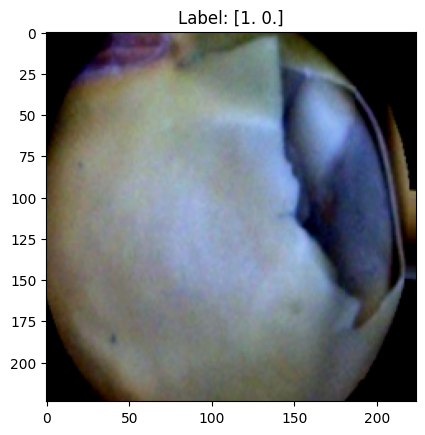

In [ ]:
# Visualizing a sample image and its label
images, labels = next(validation_generator)
plt.imshow(images[12])
plt.title(f"Label: {labels[0]}")
plt.show()